# Hormone receptor and candidate genes

Run from the repository root after `python -m scripts.download_data` and `python -m scripts.run_analysis`. These notebooks use reusable functions from `src/`. Observations come from GSE45827, not from the historical coursework.

## Research question

How do selected endocrine and signalling transcripts vary across groups?

## Data and methods

Display individual normalized signals and link each candidate to adjusted statistics.

gene_symbol  log2_fold_change  adjusted_p_value
       AKT1          0.608889      5.429733e-03
      CCND1          0.165340      6.402028e-01
       CDK4          0.215783      1.659384e-01
       CDK6         -0.254899      5.593958e-01
      ERBB2          3.349501      3.651755e-13
       ESR1         -0.228339      6.734440e-01
      FOXO1         -0.452715      4.086333e-02
      MAPK1          0.027656      8.666369e-01
      MKI67          2.716102      7.818329e-11
       MTOR          0.108514      2.918031e-01
        PGR         -4.993049      1.572249e-07
     PGRMC1         -0.125732      5.252630e-01
     PIK3CA         -0.276029      3.668045e-01
        RB1         -0.057978      7.554143e-01
  TNFRSF11A         -0.058033      9.234158e-01
    TNFSF11         -0.149319      7.693374e-01
       WNT4          0.547504      4.042603e-01
Not mapped: ['CYP19A1']


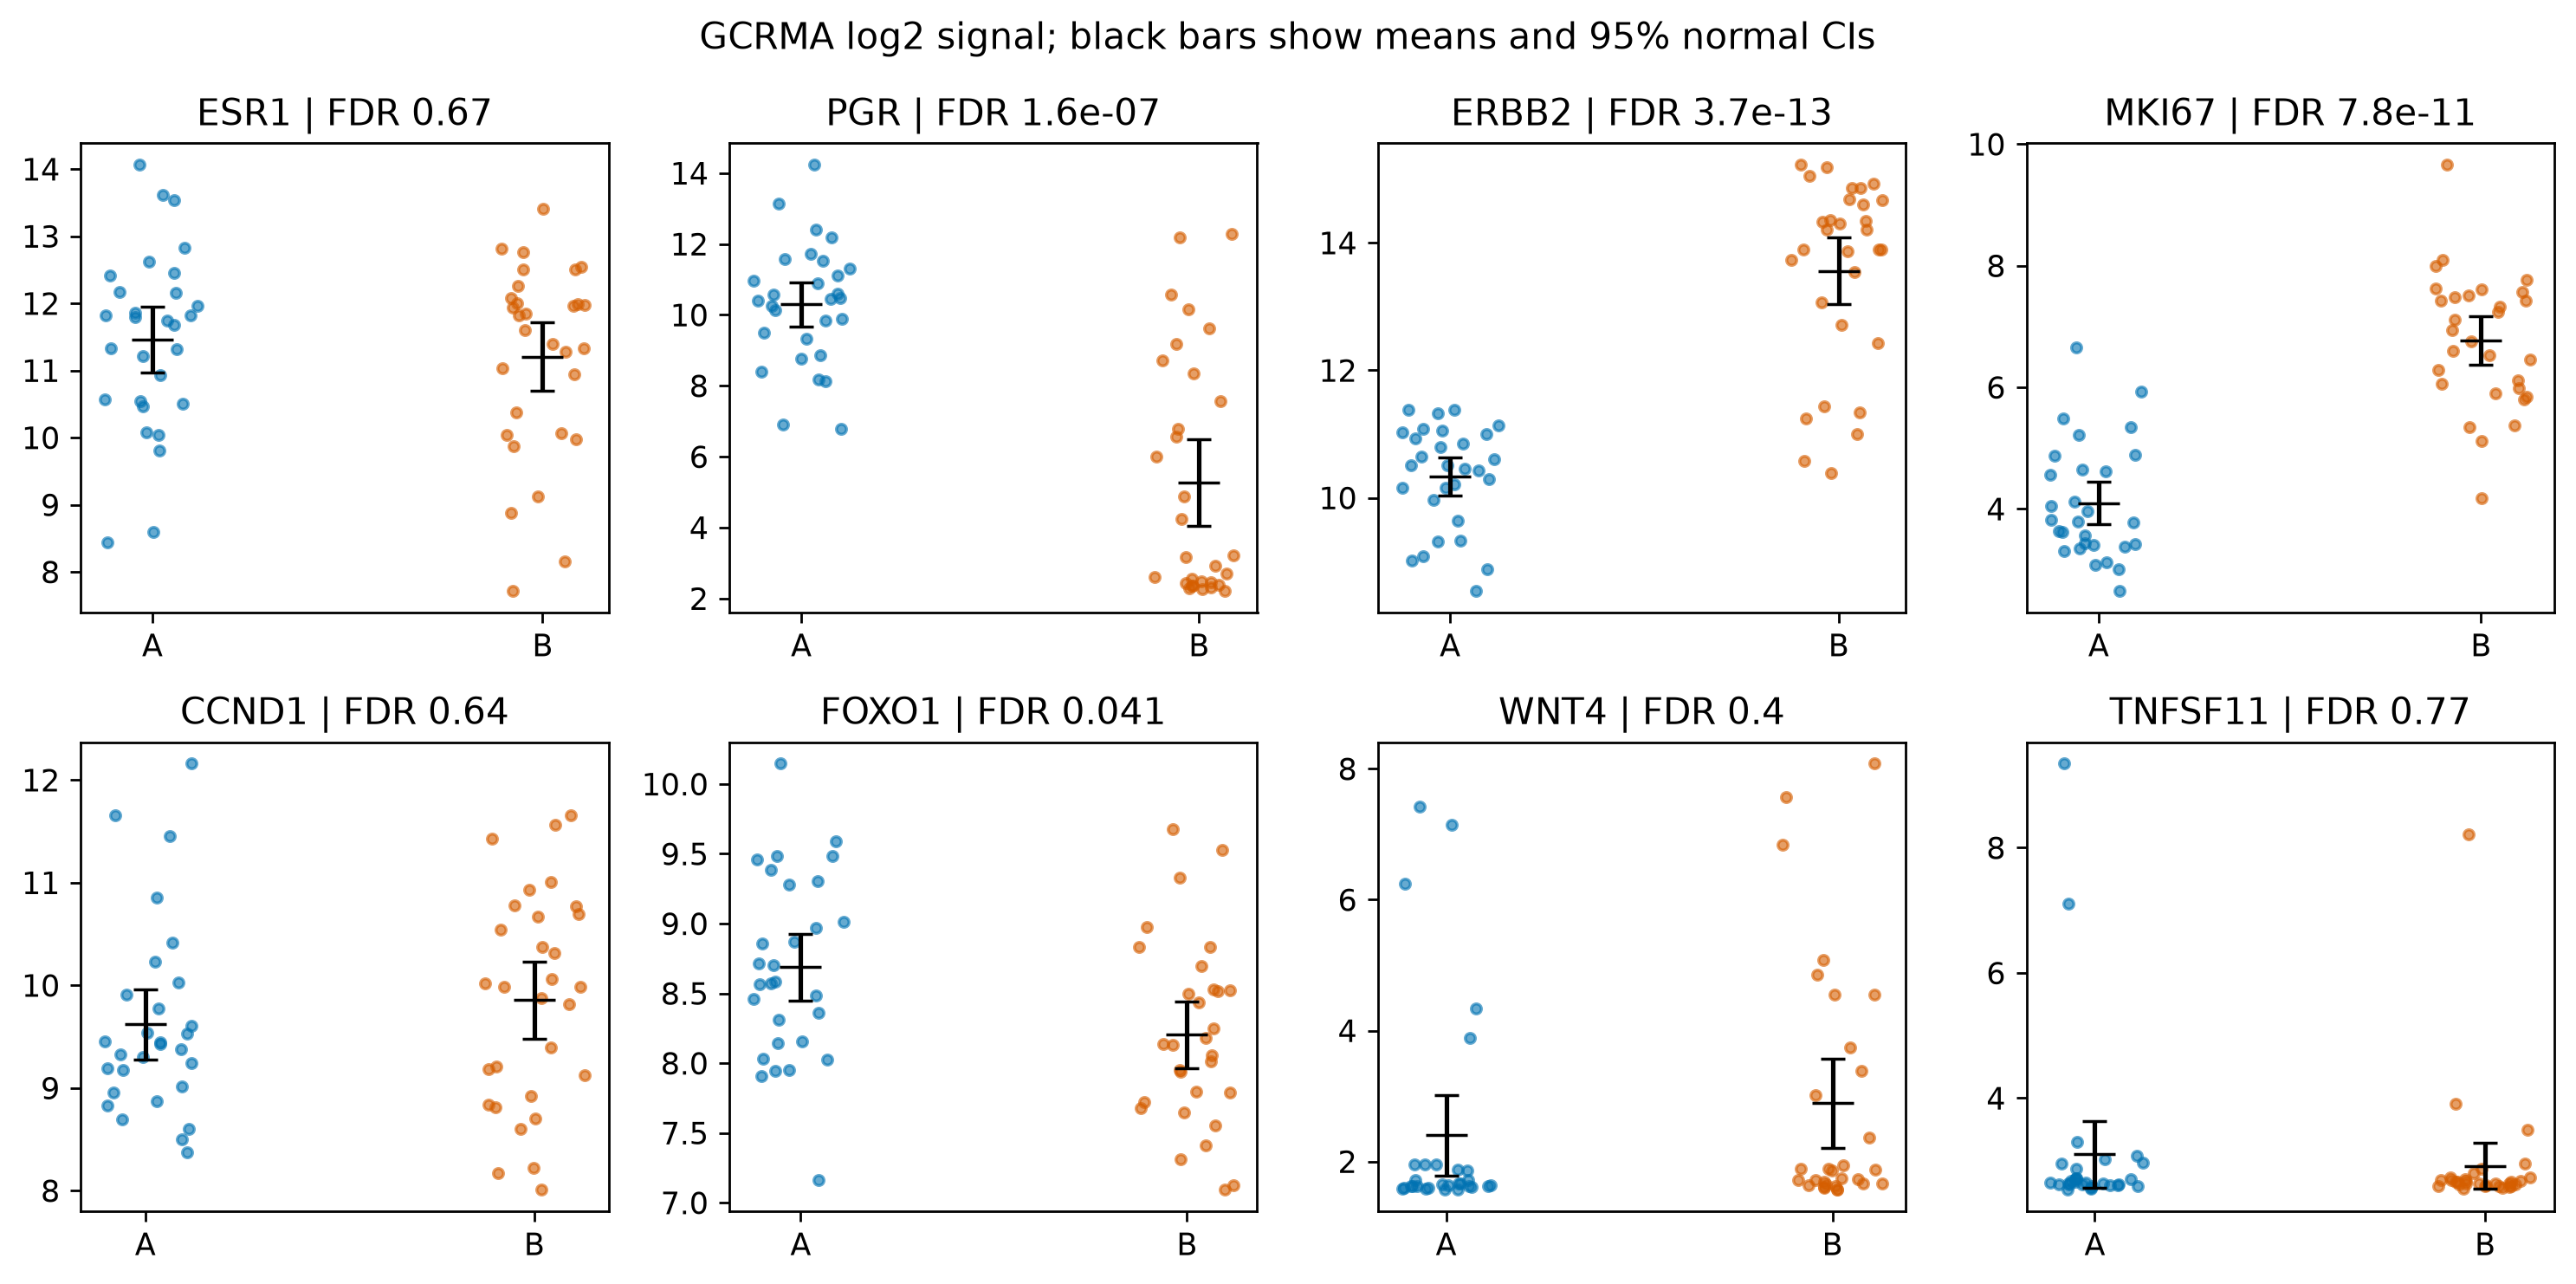

In [1]:
from pathlib import Path
import pandas as pd
from src.visualization import marker_plot
genes = pd.read_csv('data/processed/gene_expression.csv.gz', index_col=0)
metadata = pd.read_csv('data/metadata/sample_metadata.csv')
de = pd.read_csv('results/differential_expression.csv')
candidates = ['ESR1','PGR','ERBB2','MKI67','CCND1','CDK4','CDK6','RB1','FOXO1','PIK3CA','AKT1','MTOR','MAPK1','TNFSF11','TNFRSF11A','WNT4','PGRMC1','CYP19A1']
print(de.loc[de.gene_symbol.isin(candidates),['gene_symbol','log2_fold_change','adjusted_p_value']].sort_values('gene_symbol').to_string(index=False))
print('Not mapped:', sorted(set(candidates)-set(genes.index)))
marker_plot(genes, metadata, de, Path('figures'))
from IPython.display import display, Image
display(Image(filename='figures/05_markers.png'))

## Biological interpretation

PGR marks PR biology, ESR1 marks ERα, ERBB2 marks HER2, MKI67 marks proliferation, CCND1/CDK4/6/RB1 mark cell-cycle control, FOXO1 and PI3K/AKT/MTOR mark growth signalling, and TNFSF11/TNFRSF11A/WNT4 mark possible paracrine programmes. Report each observed coefficient and FDR rather than assuming candidates are differential.

## Limitations

Microarray transcript abundance does not measure protein abundance, receptor activity, phosphorylation, cell type or drug response. Missing platform genes are not biologically absent.